# Dynamic diffraction of Silicon

This notebook walks through dynamic electron diffraction with pyEMAPS, step by step. It follows
the *si_bloch.py* sample, one step per cell, so you can stop at each step, look at the result,
change a value and run it again.

You'll:

1. simulate a CBED pattern with the Bloch wave method and look at the result;
2. see how the sampling points shape the image;
3. watch the pattern change as the sample gets thicker;
4. see how the tilt and the zone axis change which beams are excited.

**Dynamic theory in brief.** In a crystal more than a few nanometres thick, an electron is
scattered many times: into a reflection, back out of it, into other reflections and back into
the direct beam. Kinematic theory, in the [kinematic diffraction notebook](si_dif.ipynb), counts
only one scattering. It gets the geometry right, but not the intensities. The Bloch wave method
solves for the electron wave inside the crystal's periodic potential. The wave is a sum of
*Bloch waves*, the eigenvectors of a matrix built from the structure factors of the beams
included. The Bloch waves have slightly different wave vectors along the beam, so as they travel
through the crystal they drift in and out of phase, and every beam's intensity changes with the
sample thickness.

pyEMAPS' simulations follow the kinematic and dynamic theory in J. C. H. Spence and J. M. Zuo,
*Electron Microdiffraction* (Plenum, 1992). This notebook points to its chapters along the way.

**Requirements.** pyEMAPS on Windows, with Python 3.12 to 3.15, and Jupyter in the same
environment:

```
pip install pyemaps jupyter
```

The [Dynamic diffraction guide](https://emlab-solutions.github.io/pyemaps/user_guide/dynamic.html)
covers the same ground.

## The theory in equations

*You can skip this section on a first read and come back to it.* Spence and Zuo derive it in
full in chapter 3, *Theory*; signs and factors of 2π differ between textbooks.

Inside the crystal, the electron wave is a sum of Bloch waves *j*, each a sum over the beams
$\mathbf g$ included:

$$\psi(\mathbf r) = \sum_j \alpha_j \sum_{\mathbf g} C^{(j)}_{\mathbf g}\,
e^{2\pi i\, (\mathbf k + \gamma_j \mathbf n + \mathbf g) \cdot \mathbf r}$$

where $\mathbf n$ is the normal to the sample surface. Putting this into the Schrödinger equation,
with the high-energy approximation, gives an eigenvalue problem for each Bloch wave's
coefficients $C_{\mathbf g}$ and its eigenvalue $\gamma$:

$$2K s_{\mathbf g}\, C_{\mathbf g} + \sum_{\mathbf h \neq \mathbf g} U_{\mathbf g - \mathbf h}\,
C_{\mathbf h} = 2K\gamma\, C_{\mathbf g}$$

Here $K$ is the electron's wave number in the crystal, $s_{\mathbf g}$ the excitation error, and
$U_{\mathbf g}$ the structure factors in 1/Å², which pyEMAPS' `generateCSF` calculates with
`sftype=3`. At the entrance surface only the direct beam exists, which fixes the $\alpha_j$. At
thickness $t$, the beams' amplitudes are

$$\phi_{\mathbf g}(t) = \sum_j C^{(j)}_{\mathbf g}\, \alpha_j\, e^{2\pi i \gamma_j t}$$

and their intensities $I_{\mathbf g} = |\phi_{\mathbf g}|^2$. In matrix form, the amplitudes are the
first column of the **scattering matrix** $S(t) = C\, e^{2\pi i \Gamma t}\, C^{-1}$, where
$\Gamma$ is the diagonal matrix of the eigenvalues. pyEMAPS' `getSCMatrix` returns $S$ and the
eigenvalues at one sampling point; the *si_scm.py* sample shows how.

**Absorption.** Inelastic scattering takes electrons out of the elastic wave. It enters as an
imaginary part of the structure factors, $U_{\mathbf g} + iU'_{\mathbf g}$, so the eigenvalues
$\gamma_j$ become complex, and each Bloch wave decays as it goes deeper into the crystal.

## Step 1: Import pyEMAPS and load a crystal

`BImgList` holds dynamic diffraction images, each with the controls it was made with, and
`showBloch` displays them. `EMC` and `SIMC` hold the microscope and simulation controls. Load
Silicon from the built-in crystals, as in the kinematic diffraction notebook.

In [1]:
from importlib.metadata import version

from pyemaps import EMC, SIMC, BImgList, Crystal, showBloch

print('pyEMAPS', version('pyemaps'))

silicon = Crystal.from_builtin('Silicon')

pyEMAPS 2.2.0


## Step 2: Simulate a CBED pattern

`generateBloch` runs a Bloch wave simulation. Dynamic diffraction is always simulated as CBED:
the beam converges onto the sample in a cone, so each diffracted beam is a disk, and each point
inside a disk is a slightly different incident direction. pyEMAPS solves the Bloch wave problem
at a set of these directions, the *sampling points*, and builds the disks from them. `sampling`
is the number of points along a disk's radius.

It returns a `BImgList` with one image per sample thickness; here, one image at the default
thickness of 200 Å.

In [2]:
images = silicon.generateBloch(sampling=20)

emc, image = images[0]
print(emc)

Electron microscope controls
  Mode                      CBED, disk size 0.16   (default Normal)
  Zone axis                 [0 0 1]
  Tilt (x, y)               (0, 0) degrees
  Shift (x, y)              (0, 0)
  Camera length             200 mm   (default 1000 mm)
  High voltage              200 kV
  Horizontal axis           (0 2 0)
  Detector pixel size       25 µm
  Detector size             512 pixels
  Objective aperture        1
Simulation controls
  Excitation error range    0.3 to 1   (default 0.3 to 2)
  Max. reciprocal vector    1 1/Å   (default 3.5 1/Å)
  Beta perturbation cutoff  0.1
  Intensity cutoff, scale   0, 5
  Max. g-list index         6
  Max. zone axis index      5
  Diagonalization cutoff    10
  Sampling points           20   (default 8)
  Sample thickness          200 Å


The controls show what the simulation used. Without your own controls, `generateBloch` uses
a shorter camera length (200 mm), so more disks fit in the image, and includes fewer beams
(`gmax` 1 1/Å and a narrower excitation error range), so it runs faster. The sample thickness is
the last line.

The image is a NumPy array of intensities, one per detector pixel:

In [3]:
print('Image size:', image.shape)
print(f'Intensity:  {image.min():.3f} to {image.max():.3f}')

Image size: (512, 512)
Intensity:  0.000 to 0.537


## Step 3: Display the pattern

`showBloch` displays the images in a `BImgList`. The caption lists the controls that differ from
the defaults. Unlike the kinematic pattern, the disks aren't uniform: the intensity varies across
each one, because every point in a disk is a different incident direction, with its own
dynamic solution.

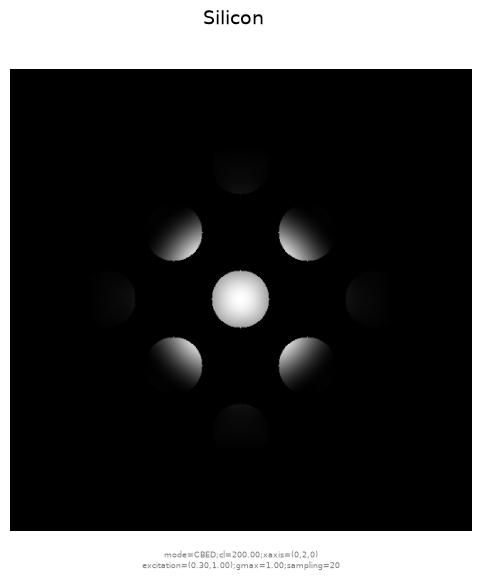

In [4]:
showBloch(images)

`bColor=True` uses a color map, which shows weak intensities more clearly:

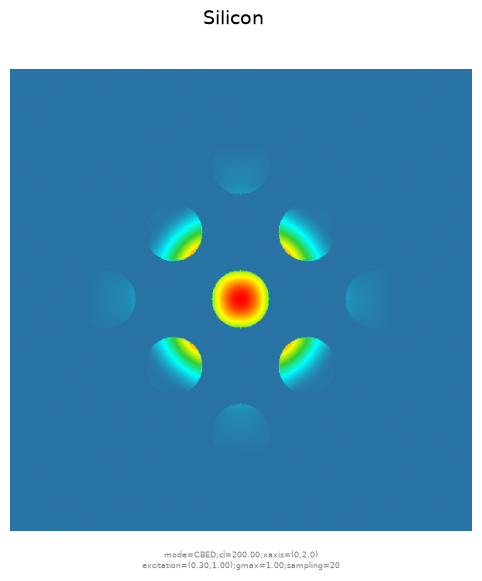

In [5]:
showBloch(images, bColor=True)

## Step 4: Sampling points

More sampling points give smoother disks, at the cost of a longer calculation. Compare 4, the
default of 8, and 40 points. A `BImgList` can collect images from several simulations: `add` takes
the controls and the image of each.

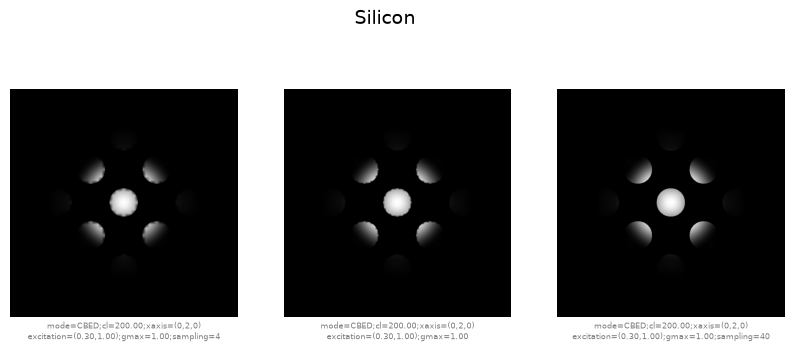

In [6]:
samplings = BImgList('Silicon')
for n in (4, 8, 40):
    emc, image = silicon.generateBloch(sampling=n)[0]
    samplings.add(emc, image)

showBloch(samplings, layout='table')

With 4 points, the disk edges are jagged; with 40, they're smooth. The middle caption has
no `sampling`, since 8 is the default.

## Step 5: Sample thickness

Dynamic intensities depend on how far the electrons travel through the crystal. `sample_thickness`
is a range, `(start, end, step)` in Å, and `generateBloch` returns one image per thickness. This
series uses the [111] zone axis at 100 kV, with a camera length of 1000 mm, so the direct beam's
(0 0 0) disk fills the view. `sort` puts the images in order of thickness.

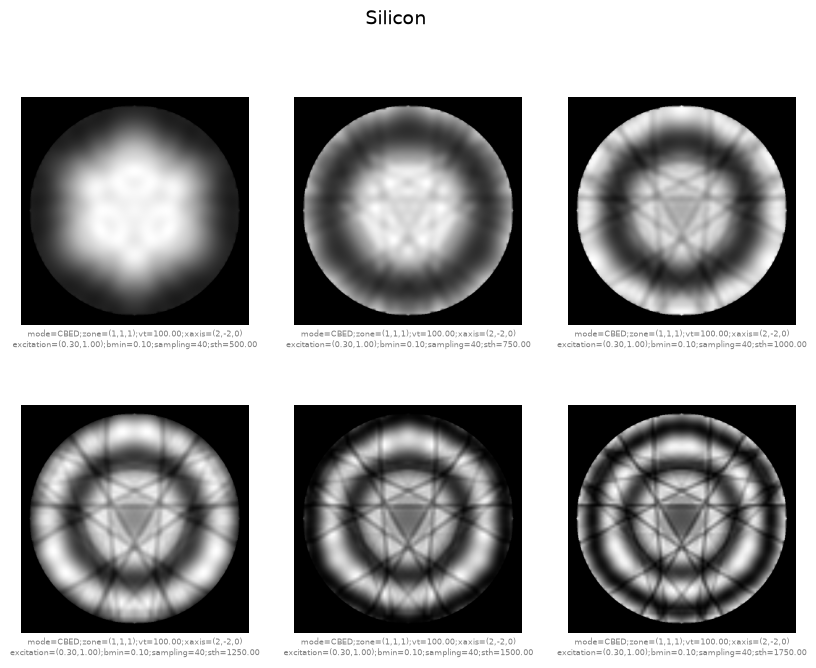

In [7]:
emc = EMC(zone=(1, 1, 1), vt=100, cl=1000, simc=SIMC(excitation=(0.3, 1.0), bmin=0.1))
thicknesses = silicon.generateBloch(sampling=40, em_controls=emc,
                                    sample_thickness=(500, 1750, 250))
thicknesses.sort()

showBloch(thicknesses, layout='table')

The dark lines that form a triangle and a star are HOLZ lines, from the higher-order Laue
zones. They stay in place, because their positions depend only on the geometry, and grow sharper
as the sample gets thicker. The broad bright and dark bands change at every step, because they
come from the interference between the Bloch waves, which depends on the thickness.

### The direct beam's intensity

To see the thickness dependence directly, follow the intensity at the center of the (0 0 0) disk
through 120 thicknesses, from 25 to 3000 Å. A smaller detector (`det_size=256`) uses a quarter of
the memory for the 120 images.

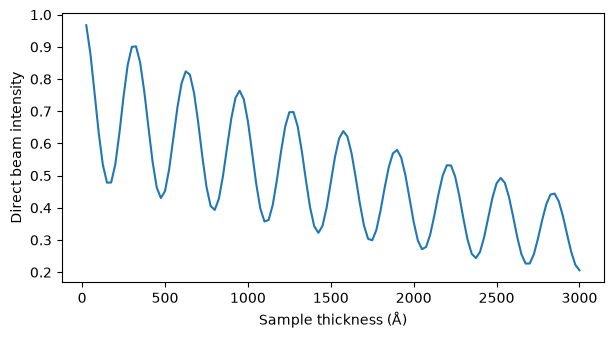

Maxima at [325, 625, 950, 1275, 1575, 1900, 2200, 2525, 2850] Å
Average spacing: 316 Å


In [8]:
import matplotlib.pyplot as plt
import numpy as np

series = silicon.generateBloch(sampling=20, det_size=256, sample_thickness=(25, 3000, 25))

center = series[0][1].shape[0] // 2
thickness = np.array([emc.simc.sth for emc, image in series])
intensity = np.array([image[center - 2:center + 3, center - 2:center + 3].mean()
                      for emc, image in series])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(thickness, intensity)
ax.set_xlabel('Sample thickness (Å)')
ax.set_ylabel('Direct beam intensity')
plt.show()

peaks = [int(thickness[i]) for i in range(1, len(intensity) - 1)
         if intensity[i - 1] < intensity[i] >= intensity[i + 1]]
print('Maxima at', peaks, 'Å')
print(f'Average spacing: {np.diff(peaks).mean():.0f} Å')

The direct beam's intensity rises and falls as the sample gets thicker: electrons are
scattered out of the direct beam into the diffracted beams, and back in. This is the
*Pendellösung* effect, and kinematic theory can't show it, since it never takes intensity away
from the direct beam. The swings slowly fade and the average falls, because the crystal also
absorbs electrons.

### Comparing with two-beam theory

How fast should it swing? In the simplest case, with only the direct beam and one reflection
$\mathbf g$, exactly at the Bragg condition and without absorption, the equations above give

$$I_{\mathbf 0}(t) = \cos^2\!\left(\frac{\pi t}{\xi_{\mathbf g}}\right), \qquad
I_{\mathbf g}(t) = \sin^2\!\left(\frac{\pi t}{\xi_{\mathbf g}}\right), \qquad
\xi_{\mathbf g} = \frac{K}{|U_{\mathbf g}|}$$

The intensity passes back and forth between the two beams with a period of $\xi_{\mathbf g}$, the
**extinction distance**. `generateCSF` gives Silicon's $U_{\mathbf g}$ at 200 kV, and from them
the extinction distances of its two strongest reflections:

In [9]:
import math

h, m0, e, c = 6.62607015e-34, 9.1093837015e-31, 1.602176634e-19, 299792458.0   # SI units
E = 200e3                                                                     # 200 kV, in V
K = math.sqrt(2 * m0 * e * E * (1 + e * E / (2 * m0 * c**2))) / h * 1e-10       # 1/λ, in 1/Å

for sf in silicon.generateCSF(kv=200, smax=0.27, sftype=3, aptype=1)[1:]:
    if sf['amp_re'] > 1e-6:     # skip the forbidden reflections, whose U_g is zero
        print(f"{sf['hkl']}: |U_g| = {sf['amp_re']:.4f} 1/Å², "
              f"extinction distance {K / sf['amp_re']:4.0f} Å")

(1, 1, 1): |U_g| = 0.0504 1/Å², extinction distance  791 Å
(0, 2, 2): |U_g| = 0.0400 1/Å², extinction distance  998 Å


The [001] zone axis has no (1 1 1)-type beams in its zero-order Laue zone; its strongest are
the four (2 2 0)-type beams. Two-beam theory puts their extinction distance near 1000 Å, yet the
direct beam swings about three times faster. At the zone axis, the direct beam exchanges
electrons with all four (2 2 0) beams, and others, at the same time. Many-beam effects like this
are why the Bloch wave method includes all the beams.

Thickness fringes measure a sample's thickness, and their exact profile measures structure
factors. Spence and Zuo's chapter 4, *The Measurement of Low-Order Structure Factors and
Thickness*, shows how, in conditions chosen to be close to two-beam.

## Step 6: Tilt and zone axis

The *si_bloch.py* sample makes two series of six images each: one over the crystal tilt, and one
over the zone axis. Each image here takes well under a second, so the loops below run them one
after the other. They use the sample's controls: a camera length of 200 mm and the default
simulation controls.

### Tilt

Tilting the crystal changes how close each reflection is to the Bragg condition, so the intensity
moves between the disks. Near the zone axis, many beams share it; at a degree or more, most of
it stays in the direct beam.

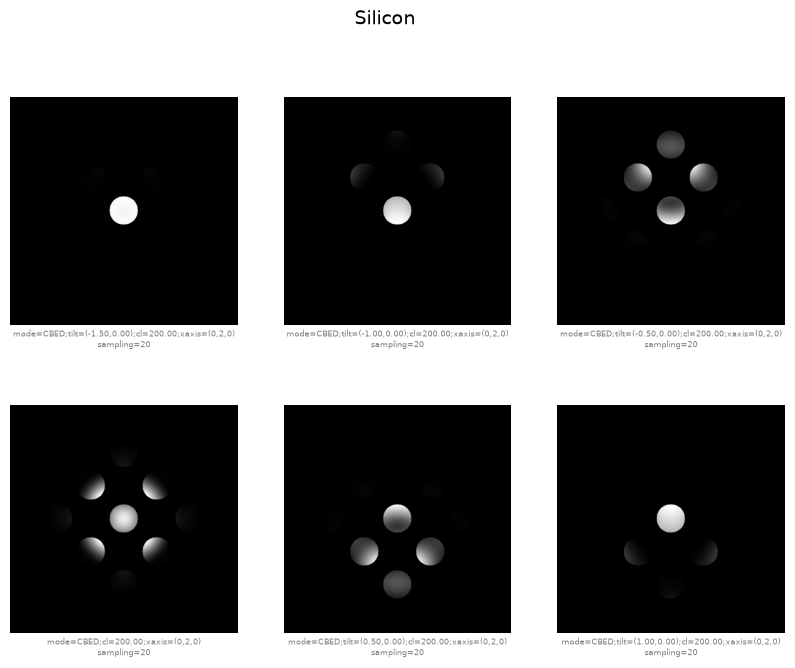

In [10]:
tilts = BImgList('Silicon')
for i in range(-3, 3):
    controls = EMC(cl=200, tilt=(i * 0.5, 0.0))
    emc, image = silicon.generateBloch(sampling=20, em_controls=controls)[0]
    tilts.add(emc, image)

tilts.sort()
showBloch(tilts, layout='table')

### Zone axis

The zone axes [0 *i* 1] cut the reciprocal lattice in different planes. The low-index zones,
[001] and [011], have many reflections near the Ewald sphere, and the electrons spread across
many disks. At the higher-index zones, [0 2 1], [0 -2 1] and [0 -3 1], few reflections are
excited, and almost all the intensity stays in the direct beam.

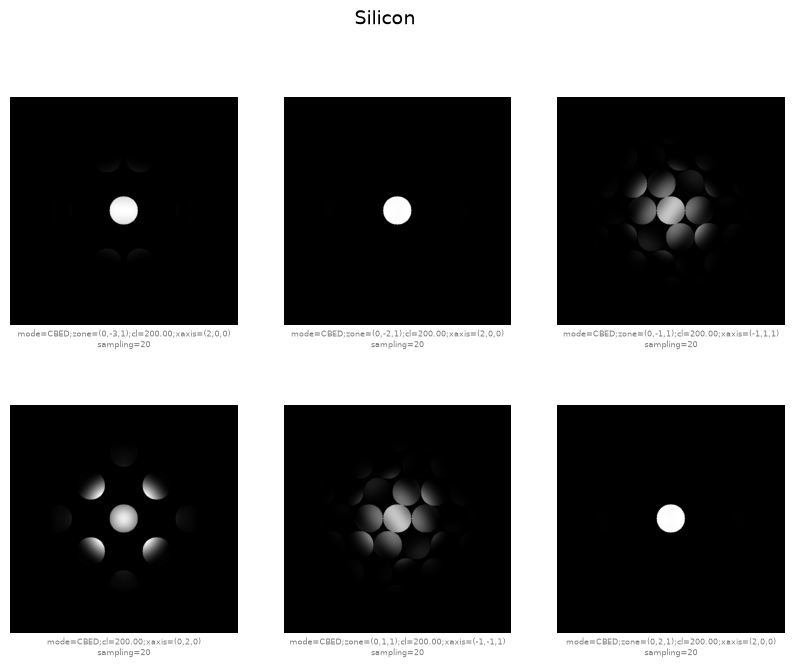

In [11]:
zones = BImgList('Silicon')
for i in range(-3, 3):
    controls = EMC(cl=200, zone=(0, i, 1))
    emc, image = silicon.generateBloch(sampling=20, em_controls=controls)[0]
    zones.add(emc, image)

zones.sort()
showBloch(zones, layout='table')

## Step 7: Save the results

`showBloch` with `bSave=True` also saves each figure as a PNG, in the `bloch` folder of the
pyEMAPS data folder: the folder named by the `PYEMAPS_DATA` environment variable, or the current
folder if it isn't set.

`generateBloch` with `bSave=True` saves the raw images instead, all thicknesses in one `.im3`
file, which [ImageJ](https://imagej.net/ij/) and DigitalMicrograph can import; see
[Third-party tools](https://emlab-solutions.github.io/pyemaps/user_guide/third_party.html). Both
print the file name.

image saved to: C:\pyemaps_data\bloch\Silicon-20261114213222.png


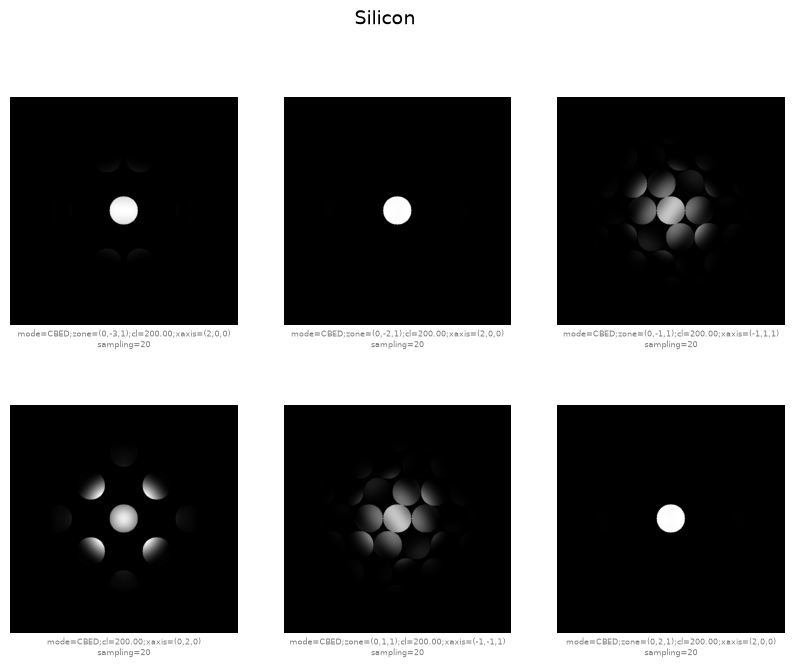

In [12]:
showBloch(zones, layout='table', bSave=True)

## Going further: many simulations in parallel

For larger simulations, *si_bloch.py* runs them in parallel processes. Its
`generate_bloch_images` function makes the same six-image tilt and zone series as above, but at
a sample thickness of 1750 Å, and you can call it here. pyEMAPS installs the samples as
`pyemaps.samples`:

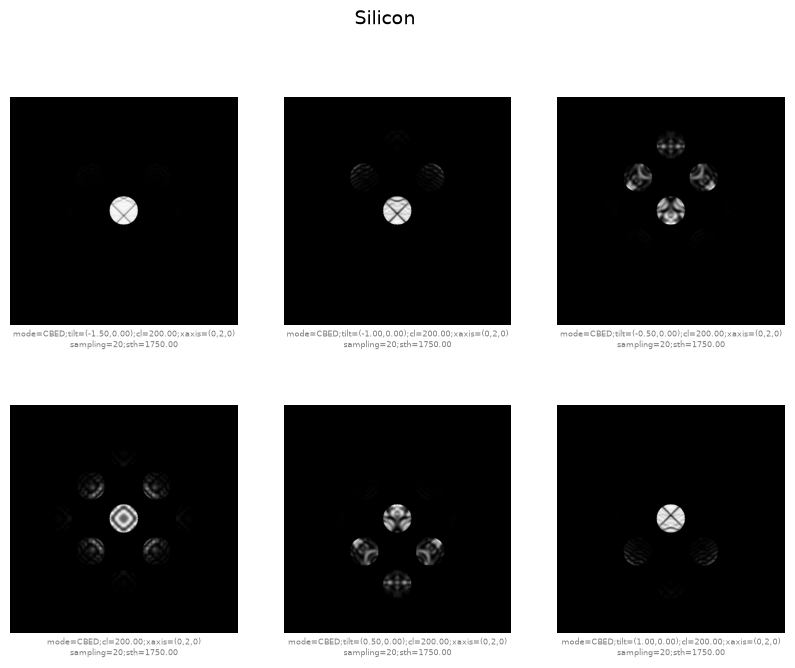

In [13]:
from pyemaps.samples.si_bloch import generate_bloch_images

series = generate_bloch_images('tilt')
showBloch(series, layout='table')

At 1750 Å, the disks are full of fine detail. The thicker the sample, the faster the
intensity changes with the incident direction across each disk, so the more fringes it shows.

To write your own parallel code, see *si_bloch.py*, which `pyemaps -cp samples` copies into
a *pyemaps_samples* folder. In a notebook on Windows, the function each process runs must come
from an importable module, such as `pyemaps.samples.si_bloch` or a `.py` file of your own; a
function defined in a notebook cell can't be sent to another process.

## Try it yourself

1. **High voltage.** Repeat the direct beam intensity curve at 100 kV and 300 kV
   (`EMC(vt=100)`). How does the spacing of the maxima change, and why?
2. **Thickness and tilt.** Make the tilt series at 500 Å and at 2000 Å. Which one changes more
   with the tilt?
3. **Another crystal.** Simulate `Germanium`, a heavier atom with Silicon's structure. Is its
   spacing of maxima longer or shorter?
4. **Disk size.** Change `disk_size` (the default is 0.16) at the [111] zone axis. What do larger
   disks show?

## Next

- The kinematic diffraction notebook, [si_dif.ipynb](si_dif.ipynb): spot and CBED patterns from
  the kinematic theory.
- [Dynamic diffraction guide](https://emlab-solutions.github.io/pyemaps/user_guide/dynamic.html)
  and the [`generateBloch` reference](https://emlab-solutions.github.io/pyemaps/api/crystals.html#pyemaps.crystals.Crystal.generateBloch).

## Further reading

J. C. H. Spence and J. M. Zuo, *Electron Microdiffraction* (Plenum, New York, 1992),
[doi:10.1007/978-1-4899-2353-0](https://doi.org/10.1007/978-1-4899-2353-0):

- chapter 3, *Theory*, for the theory section and the two-beam comparison in Step 5;
- chapter 4, *The Measurement of Low-Order Structure Factors and Thickness*, for the thickness
  fringes in Step 5.

J. M. Zuo and J. C. H. Spence, *Advanced Transmission Electron Microscopy* (Springer, New York,
2017), [doi:10.1007/978-1-4939-6607-3](https://doi.org/10.1007/978-1-4939-6607-3), a newer and
broader book by the same authors:

- chapter 5, *Dynamical Theory of Electron Diffraction for Perfect Crystals*, for the theory
  section and Step 5.